This notebook was made to answer sub question 1 of this research project: is there a greater effect on the roads that changed from 50 to 30 km/h than on the roads without a change?

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shapely
import statsmodels.api as sm
import statsmodels.formula.api as smf
from pyproj import Transformer

# crashes with their road group, made in wegvakken.ipynb
accidents = pd.read_csv("data/crashes_amsterdam_classified.csv")
accidents = accidents.rename(columns={"VKL_NUMMER": "accident_id", "JAAR_VKL": "year", "AP3_CODE": "severity",
                                      "LOCATION_TYPE": "location_type", "ROAD_GROUP": "category"})
accidents["category"] = accidents["category"].replace({"50->30": "50 to 30", "always 30": "already 30"})

print("Accidents:", len(accidents))
print()
print(accidents["category"].value_counts())
print()
print(pd.crosstab(accidents["MATCH_METHOD"], accidents["location_type"]))

Accidents: 63291

category
other              19274
50 to 30           17912
already 30         15649
stayed 50           7030
mixed               1815
unknown              824
outside network      787
Name: count, dtype: int64

location_type      junction  segment
MATCH_METHOD                        
dertig_id                 0    29596
junction              20343        0
junction_location       288        0
none                      3      183
nwb_location              0    10998
speed_fallback            4      152
street_name               0     1724


In [2]:
with open("data/amsterdam_dertig.json") as f:
    features = json.load(f)["features"]

roads = pd.DataFrame([feat["properties"] for feat in features])
geoms = [shapely.geometry.shape(feat["geometry"]) for feat in features]


def road_category(old, new):
    if old == "GOW50" and new in ("GOW30", "ETW30"):
        return "50 to 30"
    if old == "GOW50" and new == "GOW50":
        return "stayed 50"
    if old in ("ETW30", "GOW30") and new in ("ETW30", "GOW30"):
        return "already 30"
    return "other"


roads["category"] = [road_category(o, n) for o, n in zip(roads["WEGTYPE_OUD"], roads["WEGTYPE_NIEUW"])]

# convert from lat/lon to RD coordinates (metres)
to_rd = Transformer.from_crs("EPSG:4326", "EPSG:28992", always_xy=True)


def convert(xy):
    x, y = to_rd.transform(xy[:, 0], xy[:, 1])
    return np.column_stack([x, y])


lines = shapely.transform(np.array(geoms), convert)
roads["length_km"] = shapely.length(lines) / 1000

print(pd.crosstab(roads["WEGTYPE_OUD"], roads["WEGTYPE_NIEUW"]))
print()
print(roads.groupby("category").agg(segments=("WVK_ID", "size"), length_km=("length_km", "sum")).round(0))

WEGTYPE_NIEUW         BUITEN N  ETW30  ETW60  GOW30  GOW50  GOW70  SW80PLUS
WEGTYPE_OUD                                                                
BUITEN NETWERK  1515         1     75      0     13      1      0         0
ETW30              3         0  17007      0     11      1      0         0
ETW60              0         0      1    110      0      2      0         0
GOW30              0         0      0      0    287      0      0         0
GOW50              0         0    814      0   3040   1800      0         0
GOW70              0         0      0      0      0      0    113         0
SW80PLUS           0         0      0      0      0     14      0       504

            segments  length_km
category                       
50 to 30        3854      360.0
already 30     17305     1372.0
other           2353      583.0
stayed 50       1800      278.0


In [3]:
colors = {"50 to 30": "#2563A6", "stayed 50": "#E07B39", "already 30": "#3A9E6F"}
groups = ["50 to 30", "stayed 50", "already 30"]

In [4]:
data = accidents[accidents["category"].isin(groups)].copy()
data["period"] = "before"
data.loc[data["year"] == 2023, "period"] = "transition"
data.loc[data["year"] >= 2024, "period"] = "after"

pd.crosstab(data["category"], data["period"])[["before", "transition", "after"]]

period,before,transition,after
category,,,
50 to 30,13047,1783,3082
already 30,11358,1560,2731
stayed 50,4861,773,1396


In [5]:
def count_per_year(d):
    return (d.groupby(["category", "year"])
             .agg(accidents=("accident_id", "size"))
             .reset_index())


per_year = count_per_year(data)
per_year.pivot(index="year", columns="category", values="accidents")

category,50 to 30,already 30,stayed 50
year,,,
2016,2199,2171,667
2017,2211,1928,736
2018,1989,1904,693
2019,1857,1638,742
2020,1429,1091,593
2021,1587,1266,652
2022,1775,1360,778
2023,1783,1560,773
2024,1616,1314,721


In [6]:
without_2023 = per_year[per_year["year"] != 2023].copy()
without_2023["period"] = "before"
without_2023.loc[without_2023["year"] >= 2024, "period"] = "after"

summary = without_2023.groupby(["category", "period"])["accidents"].mean().unstack("period").round(1)
summary = summary[["before", "after"]]
summary["change %"] = (100 * (summary["after"] / summary["before"] - 1)).round(1)
summary.reindex(groups)

period,before,after,change %
category,,,
50 to 30,1863.9,1541.0,-17.3
stayed 50,694.4,698.0,0.5
already 30,1622.6,1365.5,-15.8


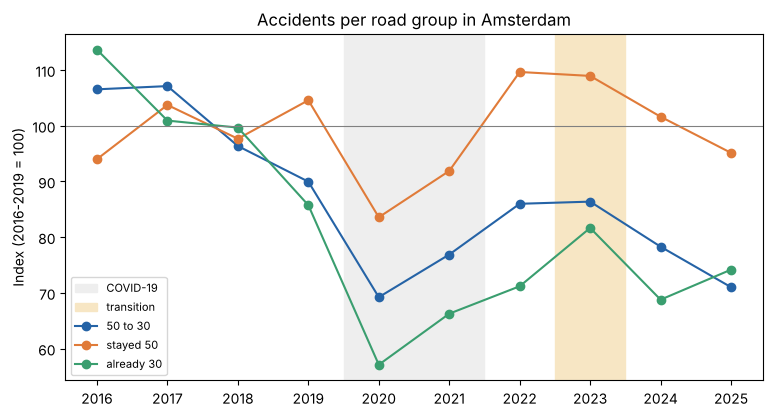

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axvspan(2019.5, 2021.5, color="#EEEEEE", label="COVID-19")
ax.axvspan(2022.5, 2023.5, color="#F7E6C4", label="transition")
for cat in groups:
    d = per_year[per_year["category"] == cat].set_index("year")["accidents"]
    ax.plot(d.index, 100 * d / d.loc[2016:2019].mean(), marker="o", color=colors[cat], label=cat)
ax.axhline(100, color="grey", linewidth=0.8)
ax.set_xticks(range(2016, 2026))
ax.set_ylabel("Index (2016-2019 = 100)")
ax.set_title("Accidents per road group in Amsterdam")
ax.legend(loc="lower left", fontsize=8)
plt.savefig("RQ1_index_per_category.png", dpi=200, bbox_inches="tight")
plt.show()

In [8]:
def prepare(control, source=per_year, drop_years=(2023,)):
    d = source[source["category"].isin(["50 to 30", control]) & ~source["year"].isin(drop_years)].copy()
    d["treated"] = (d["category"] == "50 to 30").astype(int)
    d["after"] = (d["year"] >= 2024).astype(int)
    d["t"] = d["year"] - 2016
    return d


def poisson(d, formula, term):
    m = smf.glm(formula, data=d, family=sm.families.Poisson()).fit(scale="X2")
    est = np.exp(m.params[term])
    low, high = np.exp(m.conf_int().loc[term])
    return est, low, high, m.pvalues[term]


print("Pre-trend test (before years without COVID): yearly ratio treated vs control")
for control in ["stayed 50", "already 30"]:
    pre = prepare(control)
    pre = pre[pre["year"].isin([2016, 2017, 2018, 2019, 2022])]
    est, low, high, p = poisson(pre, "accidents ~ treated * t", "treated:t")
    print(control, round(est, 3), "CI:", round(low, 3), "-", round(high, 3), "p =", round(p, 3))

Pre-trend test (before years without COVID): yearly ratio treated vs control
stayed 50 0.94 CI: 0.914 - 0.967 p = 0.0
already 30 1.038 CI: 1.012 - 1.064 p = 0.003


In [9]:
did_formula = "accidents ~ C(category) + C(year) + treated:after"
trend_formula = "accidents ~ C(category) + C(year) + treated:t + treated:after"

rows = []
for control in ["stayed 50", "already 30"]:
    d = prepare(control)
    for model, formula in [("DiD", did_formula), ("DiD + trend", trend_formula)]:
        est, low, high, p = poisson(d, formula, "treated:after")
        rows.append({"control": control, "model": model, "IRR": est,
                     "CI low": low, "CI high": high, "p": p, "change %": 100 * (est - 1)})

did_results = pd.DataFrame(rows).round(3)
did_results

,control,model,IRR,CI low,CI high,p,change %
0,stayed 50,DiD,0.823,0.671,1.009,0.061,-17.745
1,stayed 50,DiD + trend,1.151,1.044,1.268,0.005,15.068
2,already 30,DiD,0.982,0.824,1.171,0.843,-1.757
3,already 30,DiD + trend,0.789,0.642,0.969,0.024,-21.121


In [10]:
segments_only = count_per_year(data[data["location_type"] == "segment"])
checks = {
    "main analysis": prepare("stayed 50"),
    "without 2020-2021": prepare("stayed 50", drop_years=(2020, 2021, 2023)),
    "road segments only": prepare("stayed 50", source=segments_only),
    "before = 2022 only": prepare("stayed 50", drop_years=(2016, 2017, 2018, 2019, 2020, 2021, 2023)),
}

rows = []
for name, d in checks.items():
    est, low, high, p = poisson(d, did_formula, "treated:after")
    rows.append({"analysis": name, "IRR": est, "CI low": low, "CI high": high, "p": p})

pd.DataFrame(rows).round(3)

,analysis,IRR,CI low,CI high,p
0,main analysis,0.823,0.671,1.009,0.061
1,without 2020-2021,0.796,0.636,0.995,0.045
2,road segments only,0.774,0.621,0.966,0.023
3,before = 2022 only,0.968,0.919,1.019,0.210


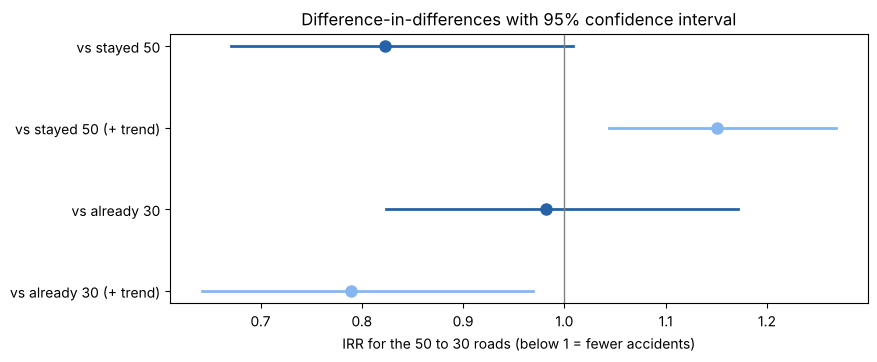

In [11]:
plot = did_results
labels = []
for i, r in plot.iterrows():
    label = "vs " + r["control"]
    if r["model"] == "DiD + trend":
        label = label + " (+ trend)"
    labels.append(label)

fig, ax = plt.subplots(figsize=(9, 3.5))
y = np.arange(len(plot))[::-1]
for yi, (_, r) in zip(y, plot.iterrows()):
    color = "#86B6EF" if r["model"] == "DiD + trend" else "#2563A6"
    ax.plot([r["CI low"], r["CI high"]], [yi, yi], color=color, linewidth=2)
    ax.plot(r["IRR"], yi, "o", color=color, markersize=8)
ax.axvline(1, color="grey", linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_xlabel("IRR for the 50 to 30 roads (below 1 = fewer accidents)")
ax.set_title("Difference-in-differences with 95% confidence interval")
plt.savefig("RQ1_did_results.png", dpi=200, bbox_inches="tight")
plt.show()

Compared with the roads that stayed 50, the 50 to 30 roads have about 18% fewer accidents (p = 0.06), but they were already dropping faster before 2023. Compared with the streets that were already 30 there is almost no difference (-2%). The pre-trends are not parallel for either control group, and when we correct for them the results go in opposite directions (+15% against the roads that stayed 50, -21% against the streets that were already 30). So the result depends on which roads we compare with, and we cannot say that the 30 km/h limit caused an extra drop on the changed roads.